# Task 2.4: optimizing the readout

The prompt asks four questions. This notebook answers them in order, (a) to (d), as a walkthrough: what we did, why, and what came out.

| | question | short answer |
|---|---|---|
| (a) | How does a readout drive enter the circuit Hamiltonian, and what else survives the RWA? | A tone at $\omega_a$ (on its own line, or as a second flux tone on the ATS) gives $\epsilon_Z(a+a^\dagger)$. Besides $g_2a^2b^\dagger$ only tiny photon-number corrections survive. What the RWA misses is the pump's own off-resonant push, which shifts frequencies: the pump must be retuned by $-23$ MHz. |
| (b) | What happens to contrast and $\Gamma_X$ as $\epsilon_Z$ grows? | Contrast grows like $\epsilon_Z$ (signal like $\epsilon_Z^2$), but so does the extra bit-flip rate, $\Delta\Gamma_X\propto\epsilon_Z^2$. At $\alpha=2.1$, $\epsilon_Z=0.5g_2$ takes $T_X$ from 2.6 s to about 1 ms while the drive is on. Past about $1.5g_2$ the cat is knocked over and the contrast collapses. |
| (c) | A strategy that reads better without hurting $\Gamma_X$ much? | Drive at the buffer's ringing frequency (about 3.1 MHz) instead of a flat pulse. Readout error in 2 µs drops from 1.12% to 0.65%. |
| (d) | Why does it work? | Memory and buffer form a damped spring (Task 2.3). Pushing in rhythm rings it up, so more signal for the same drive. The SVD-optimal pulse and the gradient optimizer, given no hint about the shape, both come back resonant. |

Everything here reads saved results from `results/s2/` (produced by the scripts named in each section), so the notebook runs in seconds.

In [1]:
from pathlib import Path
import sys, io
from contextlib import redirect_stdout
from math import factorial, exp, sqrt, pi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F, linresp
from research.s2.common import G2, KAPPA_B
from src import plotting as P
show = lambda name, w=1000: display(Image(filename=str(ROOT / "figures/s2" / f"{name}.png"), width=w))

## (a) How the readout drive gets into the circuit, and what else survives

> *Work out how a memory readout drive actually enters this circuit-level Hamiltonian, and what other terms beyond the two-photon term you've used so far survive the same expansion and rotating-wave step.*

### Step 1: the one line of circuit we care about

At the ATS bias point the prompt gives us

$$H_{\rm ATS}=2E_J\,\epsilon_p\cos(\omega_pt)\,\sin\hat\varphi,\qquad \hat\varphi=\varphi_a(a+a^\dagger)+\varphi_b(b+b^\dagger)$$

with $\varphi_a=0.06$, $\varphi_b=0.3$ (small), $E_J/2\pi=40$ GHz, $\omega_a/2\pi=4.0$, $\omega_b/2\pi=4.8$, $\omega_p/2\pi=3.2$ GHz. Nice detail: with no pump ($\epsilon_p=0$) this term is zero, so the ATS adds no static Kerr. Everything comes with the pump.

### Step 2: just expand the sine

$\hat\varphi$ is small, so write $\sin x$ as a polynomial:

$$\sin x = x-\frac{x^3}{6}+\frac{x^5}{120}-\dots,\qquad x=\varphi_a(a+a^\dagger)+\varphi_b(b+b^\dagger)$$

**First order:** $x=\varphi_a(a+a^\dagger)+\varphi_b(b+b^\dagger)$. Linear pushes on each mode.

**Third order:** $x^3$ has a piece $3\varphi_a^2\varphi_b\,(a+a^\dagger)^2(b+b^\dagger)$. Multiply out $(a+a^\dagger)^2(b+b^\dagger)$ and one of the products is $a^2b^\dagger$:

$$-\frac{x^3}{6}\;\ni\;-\frac{3\varphi_a^2\varphi_b}{6}\,a^2b^\dagger=-\frac{\varphi_a^2\varphi_b}{2}\,a^2b^\dagger$$

Put back the prefactor $2E_J\epsilon_p\cos(\omega_pt)$ and keep half of the cosine (next step explains why half):

$$|g_2|=\tfrac12E_J\,\epsilon_p\,\varphi_a^2\varphi_b$$

That is the prompt's formula. The higher orders ($x^5,x^7,\dots$) each add a little bit to the same $a^2b^\dagger$ coefficient; summed up exactly they multiply it by $e^{-(\varphi_a^2+\varphi_b^2)/2}=0.954$. So $g_2/2\pi=0.763$ MHz needs $\epsilon_p=0.037$, slightly more than the prompt's 0.035.

### Step 3: which terms survive (the spinning rule)

In the frame rotating with the modes, every $a$ spins as $e^{-i\omega_at}$ and every $b$ as $e^{-i\omega_bt}$; daggers spin the other way. The pump $\cos\omega_pt=\tfrac12(e^{i\omega_pt}+e^{-i\omega_pt})$ adds $\pm\omega_p$. A term survives only if the total spin is zero; anything else spins at GHz and averages away.

| term | spins at | with pump | survives? |
|---|---|---|---|
| $a^2b^\dagger$ | $-2\omega_a+\omega_b=-3.2$ GHz | $+\omega_p$ → **0** | **yes**: this is $g_2$ |
| $a$ | $-4.0$ GHz | $\pm3.2$ → $-0.8$ or $-7.2$ | no |
| $b$ | $-4.8$ GHz | $\pm3.2$ → $-1.6$ or $-8.0$ | no |
| $a^\dagger b$ | $+4.0-4.8=-0.8$ GHz | → $2.4$ or $-4.0$ | no |

### Step 4: how the readout drive enters

We need a static $\epsilon_Z(a+a^\dagger)$ in the rotating frame, so we need something spinning at $\omega_a$:

* **Simplest:** a separate microwave line on the memory at $\omega_a$: $2\epsilon_Z\cos(\omega_at)(a+a^\dagger)$. Keep the non-spinning half and you get exactly $\epsilon_Z(a+a^\dagger)$, the term we used in Task 2.3.
* **Through the ATS:** add a second, small flux tone $\epsilon_r\cos(\omega_at)$ next to the pump. The first-order term of the sine then gives $E_J\epsilon_r\varphi_a\,(a+a^\dagger)$, so $\epsilon_Z=E_J\epsilon_r\varphi_a e^{-\Phi/2}$. For $\epsilon_Z=0.5g_2$ that is $\epsilon_r\approx1.7\times10^{-4}$, tiny. Same rule as Step 3 then tells us which extra terms ride along with it.

The next cell runs the spinning rule over every term up to 7th order (this is `research/s2/rwa_terms.py`, extended to the readout tone) and lists the survivors.

In [2]:
WA, WB, WP = 4.0e3, 4.8e3, 3.2e3          # MHz
EJ, PA, PB = 40e3, 0.06, 0.3
Phi = PA**2 + PB**2
eps_p = 0.763 / (0.5 * EJ * PA**2 * PB * exp(-Phi / 2))

def survivors(tone, amp, order=7):
    # sin(phi) normal-ordered: e^{-Phi/2} sum_{p+q+r+s odd} i^{n-1} PA^{p+q} PB^{r+s}/(p!q!r!s!) a†^p a^q b†^r b^s
    rows = []
    for p in range(order + 1):
        for q in range(order + 1 - p):
            for r in range(order + 1 - p - q):
                for s in range(order + 1 - p - q - r):
                    n = p + q + r + s
                    if n % 2 == 0 or (p, q, r, s) > (q, p, s, r):      # odd terms only; one of each h.c. pair
                        continue
                    if abs((p - q) * WA + (r - s) * WB + tone) > 1e-6:  # must not spin
                        continue
                    c = amp * exp(-Phi / 2) * (-1) ** ((n - 1) // 2) * PA**(p + q) * PB**(r + s) / (
                        factorial(p) * factorial(q) * factorial(r) * factorial(s))
                    rows.append({"term": f"a†^{p} a^{q} b†^{r} b^{s}".replace("^0", "^0"), "order": n, "coef (MHz)": c})
    return pd.DataFrame(rows).sort_values("coef (MHz)", key=abs, ascending=False)

print(f"eps_p = {eps_p:.4f}  (e^(-Phi/2) = {exp(-Phi/2):.3f})")
print("\nPump tone at w_p: terms that stop spinning (coefficient includes the 1/2 from the cosine)")
display(survivors(WP, EJ * eps_p).style.hide(axis="index").format({"coef (MHz)": "{:.3g}"}))

eps_z = 0.5 * 0.763                          # MHz, a 0.5 g2 readout drive
amp_r = eps_z / (PA * exp(-Phi / 2))         # E_J * eps_r that produces it
print(f"\nReadout tone at w_a (eps_Z = 0.5 g2, so E_J eps_r/2pi = {amp_r:.1f} MHz, eps_r = {amp_r / EJ:.1e})")
display(survivors(WA, amp_r).style.hide(axis="index").format({"coef (MHz)": "{:.3g}"}))

eps_p = 0.0370  (e^(-Phi/2) = 0.954)

Pump tone at w_p: terms that stop spinning (coefficient includes the 1/2 from the cosine)


term,order,coef (MHz)
a†^0 a^2 b†^1 b^0,3,-0.763
a†^0 a^2 b†^2 b^1,5,0.0343
a†^1 a^3 b†^1 b^0,5,0.000916
a†^0 a^2 b†^3 b^2,7,-0.000515
a†^1 a^3 b†^2 b^1,7,-4.12e-05
a†^2 a^4 b†^1 b^0,7,-4.12e-07



Readout tone at w_a (eps_Z = 0.5 g2, so E_J eps_r/2pi = 6.7 MHz, eps_r = 1.7e-04)


term,order,coef (MHz)
a†^0 a^1 b†^0 b^0,1,0.382
a†^0 a^1 b†^1 b^1,3,-0.0343
a†^0 a^1 b†^2 b^2,5,0.000773
a†^1 a^2 b†^0 b^0,3,-0.000687
a†^1 a^2 b†^1 b^1,5,6.18e-05
a†^0 a^1 b†^3 b^3,7,-7.73e-06
a†^1 a^2 b†^2 b^2,7,-1.39e-06
a†^2 a^3 b†^0 b^0,5,4.12e-07
a†^2 a^3 b†^1 b^1,7,-3.71e-08
a†^3 a^4 b†^0 b^0,7,-1.24e-10


**Reading the two tables.**

* **Pump survivors.** The big one is $a^2b^\dagger$ at 0.763 MHz, our $g_2$. The rest are the same process with a photon-number tag on it: $a^2b^{\dagger2}b$ (0.034 MHz) means "$g_2$ grows by about 4.5% per buffer photon", and $a^\dagger a^3b^\dagger$ (0.0009 MHz) means "$g_2$ shifts by about 0.1% per memory photon", so about 0.5% at $\alpha^2=4.4$. The buffer is nearly empty, so these are small corrections to $g_2$, not new physics.
* **Readout survivors.** The big one is $a$, i.e. $\epsilon_Z(a+a^\dagger)$. The next ones, $a^\dagger a^2$ and $ab^\dagger b$, are again photon-number tags: the drive strength changes by $-\tfrac12\varphi_a^2\approx-0.2\%$ per memory photon and $-\varphi_b^2=-9\%$ per buffer photon. With $\langle a^\dagger a\rangle\approx4.4$ and a nearly empty buffer, that is about a 1% weaker drive. So a readout tone through the ATS is clean.

### Step 5: what the RWA throws away, and why it matters

The terms that spin are not harmless. The biggest is the first-order pump term on the buffer:

$$2E_J\epsilon_p\cos(\omega_pt)\,\varphi_b(b+b^\dagger):\quad\text{a push of }E_J\epsilon_p\varphi_b\approx 2\pi\times420\text{ MHz, detuned by }\omega_b-\omega_p=2\pi\times1.6\text{ GHz}$$

A strong push far off resonance makes the buffer jiggle at the pump frequency with $n_b\approx(420/1600)^2\approx0.07$ photons, and through the nonlinearity that jiggle shifts the mode frequencies (Stark shifts). Then $\omega_p=2\omega_a-\omega_b$ is no longer exactly on beat.

To see it, we simulated the full $\sin\hat\varphi$ with no RWA (`research/s2/circuit_sim.py`, 150 ns, no loss, resolving the GHz oscillations directly; we chose a short window and small truncations because that is the only way to afford it).

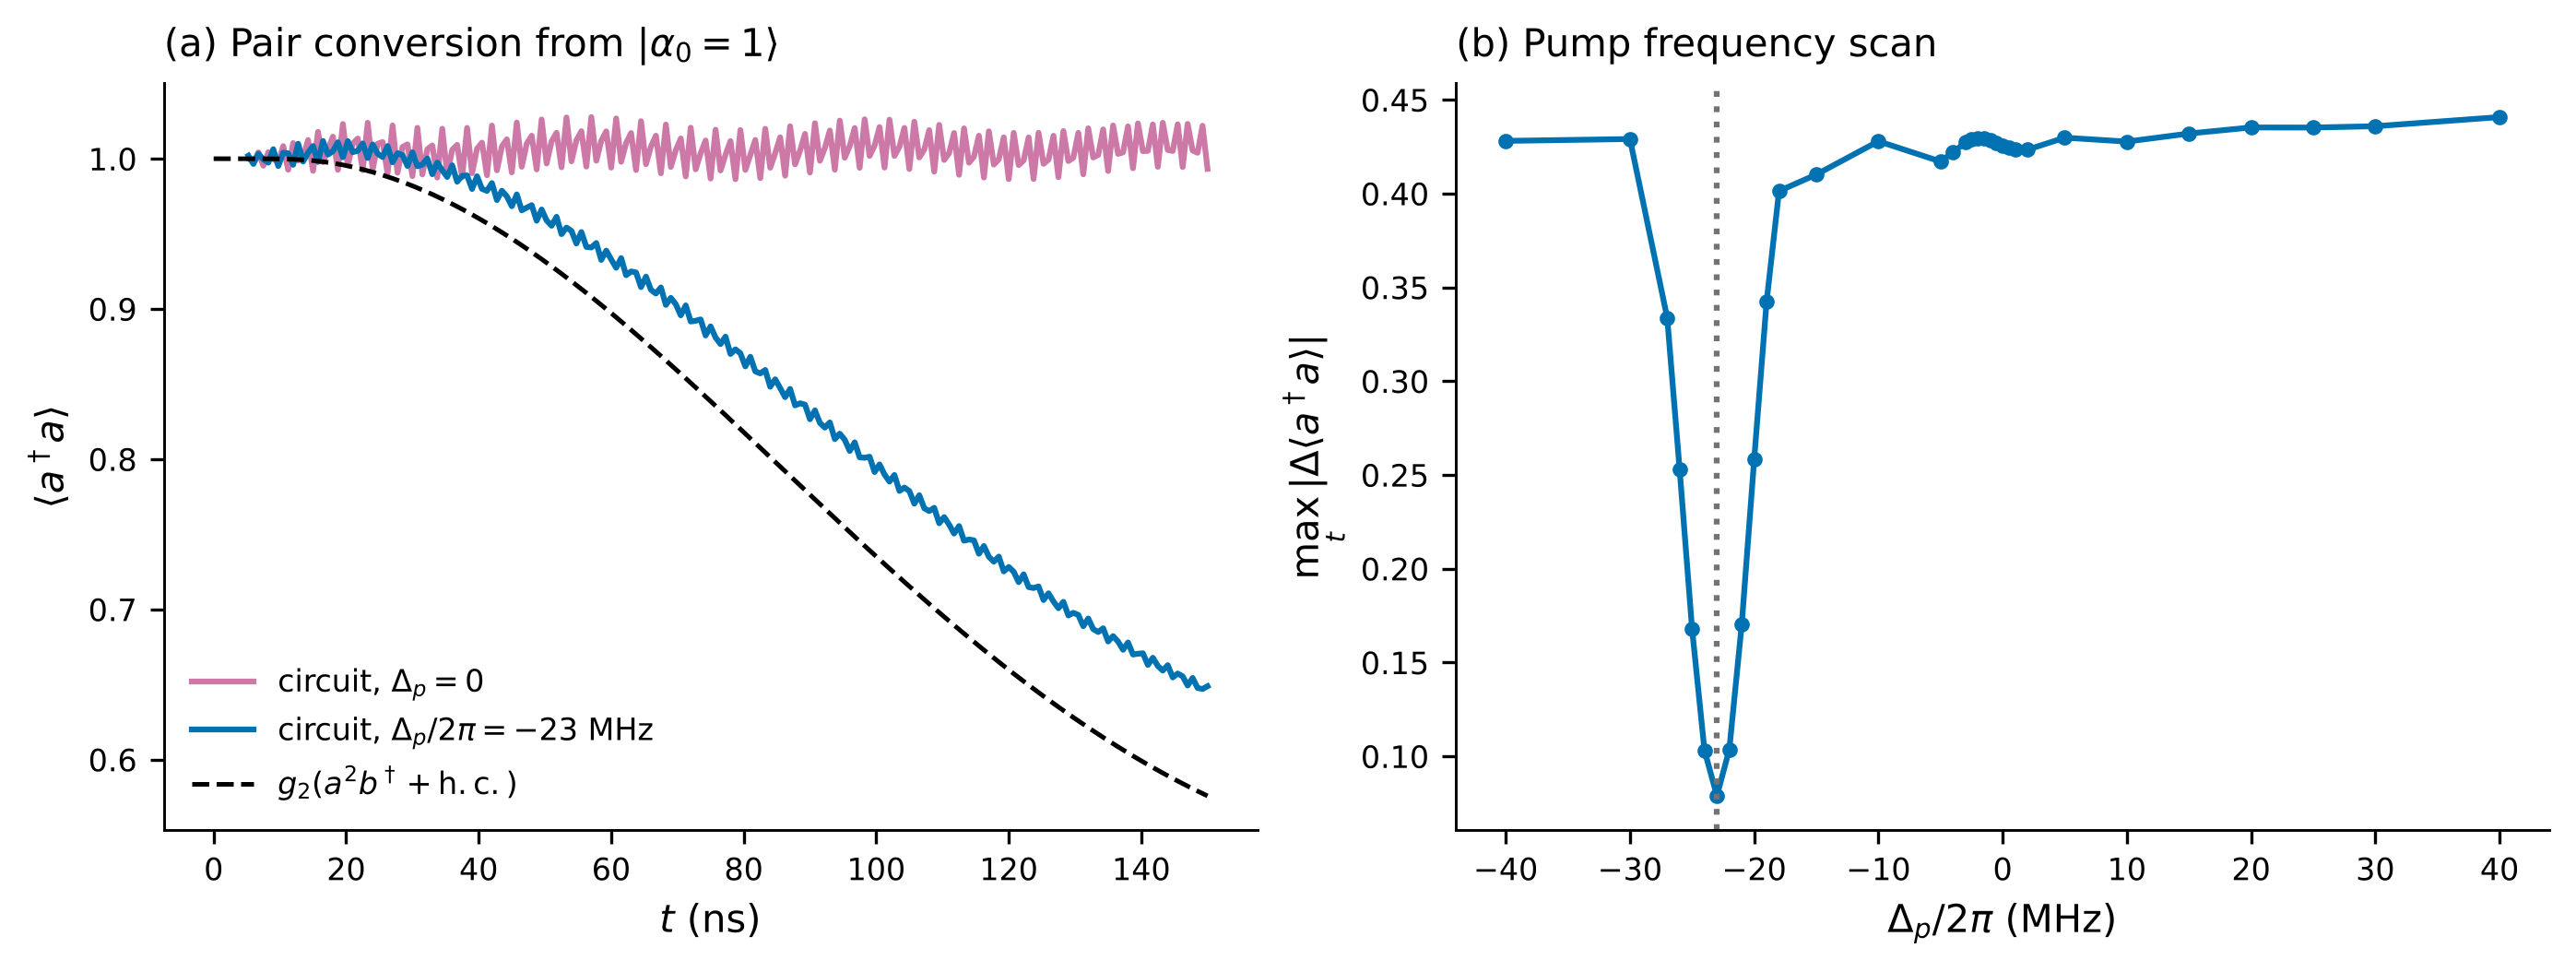

max |Δ⟨a†a⟩| vs the g2 model (6 ns average): 0.43 at the textbook pump, 0.07 with the pump moved by −23 MHz
buffer jiggle predicted from the off-resonant pump push: n_b ≈ 0.070


In [3]:
with redirect_stdout(io.StringIO()):
    F.circuit_check()
show("task_2_4_circuit")
d0, d23 = (F.load(f"circuit_na14_nb6_T0.15_dp{dp}.json")[0] for dp in (0, -23))
nb_pred = (EJ * eps_p * PB * exp(-Phi / 2) / (WB - WP))**2
print(f"max |Δ⟨a†a⟩| vs the g2 model (6 ns average): {d0['max_abs_diff_na_averaged']:.2f} at the textbook pump, "
      f"{d23['max_abs_diff_na_averaged']:.2f} with the pump moved by −23 MHz")
print(f"buffer jiggle predicted from the off-resonant pump push: n_b ≈ {nb_pred:.3f}")

**What this shows.** (a) Start with $|\alpha_0=1\rangle$ and an empty buffer and watch photon pairs convert. At the textbook pump frequency (pink) almost nothing converts: the Stark shifts have pushed the process off beat. Move the pump down by 23 MHz (blue) and the circuit follows the $g_2$ model (dashed), about 15% slower, so the real $g_2$ is a bit smaller. (b) Scanning the pump frequency gives one sharp dip at $-23$ MHz. Same answer at $12\times5$ and $14\times6$.

**Answer to (a).** The readout drive is a tone at $\omega_a$, either on its own line or as a second flux tone on the ATS, and it gives $\epsilon_Z(a+a^\dagger)$ with only about 1% photon-number corrections. Besides $g_2a^2b^\dagger$, the RWA keeps only photon-number-dependent corrections to $g_2$ of a few percent. The important thing it misses is the off-resonant pump push, which Stark-shifts the modes; in the real circuit the pump has to be retuned by about $-23$ MHz.

## (b) Turning up $\epsilon_Z$: contrast vs bit flips

> *Numerically investigate what happens to your readout contrast (Task 2.3) and to $\Gamma_X$ (Task 2.1) as you increase $\epsilon_Z$. Is there a trade-off? Where does it come from physically?*

### What we ran

* **Contrast:** the Task 2.3 readout simulation (`research/s2/readout.py`) at $\alpha=2.1$ for $\epsilon_Z$ from $0.05$ to $3g_2$. We read the settled $\langle b\rangle$ and compare with the linear prediction $\mp\epsilon_Z/(2\alpha g_2)$.
* **Bit flips:** the Task 2.1 eigenvalue method with the drive switched on (`research/s2/gx_eig.py --eps-z`), at $\alpha=1.0,1.4,1.8,2.1$. One change from 2.1: the drive $\epsilon_Z(a+a^\dagger)$ is *not* symmetric under $a\to-a$, so the even/odd split no longer holds. We take the smallest nonzero eigenvalue of the full Liouvillian instead. Spot-checked against time-domain fits at $\alpha=1.0,1.4$ (agree to $10^{-8}$ to $10^{-3}$).

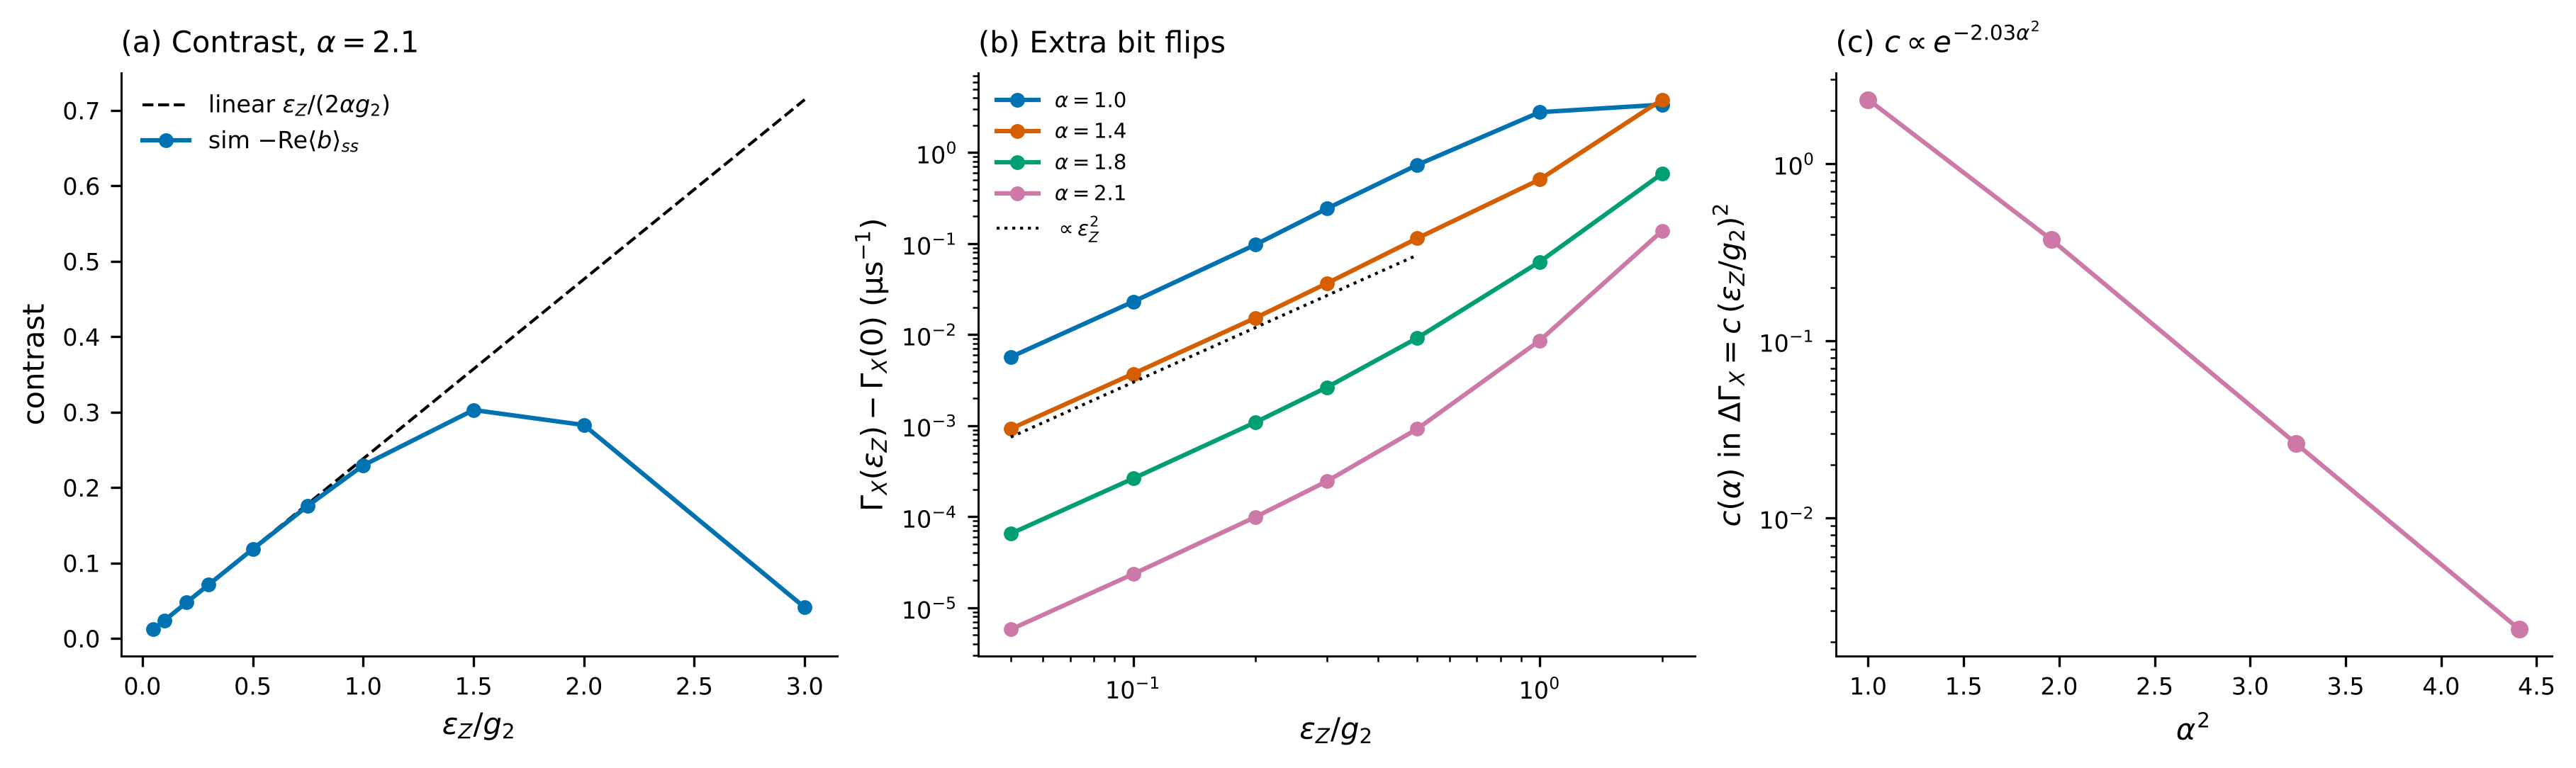

ε_Z/g₂,Γ_X (1/µs),time per flip,contrast −Re⟨b⟩,SNR over 4 µs
0,3.85e-07,2.6 s,—,—
0.05,6.16e-06,162 ms,0.0119,0.037
0.1,2.38e-05,42 ms,0.0238,0.148
0.2,9.99e-05,10 ms,0.0476,0.592
0.3,0.000247,4.05 ms,0.0713,1.33
0.5,0.000924,1.08 ms,0.1184,3.68
1,0.00861,116 µs,0.2293,14.2
2,0.138,7.24 µs,0.2829,37


c(alpha) falls as exp(-2.03 alpha^2)


In [4]:
def gx_by_eps(alpha):
    rows = [d for d in F.load(f"gx_two_a{alpha:.2f}_*.json")
            if d["n_th"] == 0 and abs(d["kappa_a"] / (2 * pi) - 9.3e-3) < 1e-9 and abs(d["kappa_b"] / (2 * pi) - 2.6) < 1e-9]
    best = {}
    for d in rows:                                            # largest truncation per eps_Z
        k = d["eps_z_over_g2"]
        if k not in best or d["na"] * d["nb"] > best[k]["na"] * best[k]["nb"]:
            best[k] = d
    return {k: best[k]["gamma_x"] for k in sorted(best)}

ro = F.load("readout_a2.10_32x8_T4.json")[0]["runs"]
eps = np.array([r["eps_over_g2"] for r in ro])
bss = np.array([r["b_ss"][0] for r in ro]); blin = np.array([r["b_ss_linear"] for r in ro])
alphas = (1.0, 1.4, 1.8, 2.1)
gx = {a: gx_by_eps(a) for a in alphas}
c = np.array([(gx[a][0.1] - gx[a][0.0]) / 0.1**2 for a in alphas])   # Delta Gamma_X = c eps^2
slope = np.polyfit(np.array(alphas)**2, np.log(c), 1)[0]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
ax[0].plot(eps, -blin, "k--", lw=1, label=r"linear $\epsilon_Z/(2\alpha g_2)$")
ax[0].plot(eps, -bss, "o-", color="C0", ms=4, label=r"sim $-\mathrm{Re}\langle b\rangle_{ss}$")
ax[0].set(xlabel=r"$\epsilon_Z/g_2$", ylabel="contrast"); ax[0].legend()
P.panel(ax[0], "a", r"Contrast, $\alpha=2.1$")
for i, a in enumerate(alphas):
    e = np.array([k for k in gx[a] if k > 0]); g = np.array([gx[a][k] for k in e])
    ax[1].loglog(e, g - gx[a][0], "o-", color=f"C{i}", ms=4, label=rf"$\alpha={a}$")
ee = np.array([0.05, 0.5]); ax[1].loglog(ee, 0.3 * ee**2, "k:", lw=1, label=r"$\propto\epsilon_Z^2$")
ax[1].set(xlabel=r"$\epsilon_Z/g_2$", ylabel=r"$\Gamma_X(\epsilon_Z)-\Gamma_X(0)$ (µs$^{-1}$)"); ax[1].legend(fontsize=7)
P.panel(ax[1], "b", "Extra bit flips")
ax[2].semilogy(np.array(alphas)**2, c, "o-", color="C3", ms=5)
ax[2].set(xlabel=r"$\alpha^2$", ylabel=r"$c(\alpha)$ in $\Delta\Gamma_X=c\,(\epsilon_Z/g_2)^2$")
P.panel(ax[2], "c", rf"$c\propto e^{{-{-slope:.2f}\alpha^2}}$")
with redirect_stdout(io.StringIO()):
    P.save(fig, "s2/task_2_4_drive_sweep")
plt.close(fig); show("task_2_4_drive_sweep", 1100)

g21 = gx[2.1]
def per_flip(g):
    us = 1 / g
    return f"{us / 1e6:.2g} s" if us >= 1e6 else f"{us / 1e3:.3g} ms" if us >= 1e3 else f"{us:.3g} µs"
snr_end = lambda r: r["snr"][-1] if isinstance(r["snr"], list) else r["snr"]
rows = []
for k in g21:
    i = list(eps).index(k) if k in eps else None
    rows.append({"ε_Z/g₂": f"{k:g}", "Γ_X (1/µs)": f"{g21[k]:.3g}", "time per flip": per_flip(g21[k]),
                 "contrast −Re⟨b⟩": f"{-bss[i]:.4f}" if i is not None else "—",
                 "SNR over 4 µs": f"{snr_end(ro[i]):.3g}" if i is not None else "—"})
display(pd.DataFrame(rows).style.hide(axis="index"))
print(f"c(alpha) falls as exp(-{-slope:.2f} alpha^2)")

**What the plots say.**

* **(a) Contrast** follows the straight line $\epsilon_Z/(2\alpha g_2)$ to within 1% up to $0.5g_2$ and 4% at $1g_2$. Past about $1.5g_2$ it bends over and then collapses: the drive is strong enough to knock the cat out of its well ($\mathrm{Re}\langle a\rangle$ drops from 2.1 to 1.2 at $2g_2$).
* **(b) Extra bit flips** follow a slope-2 line: $\Gamma_X(\epsilon_Z)-\Gamma_X(0)=c(\alpha)\,\epsilon_Z^2$, cleanly up to about $0.3g_2$.
* **The size of the effect is brutal.** At $\alpha=2.1$, the drive-free cat flips once every 2.6 s. With $\epsilon_Z=0.5g_2$ on, it flips about once per millisecond. That is fine for a 2 µs readout, but it is the price.

**Is there a trade-off? Yes.** The signal (SNR) grows as contrast squared, so $\propto\epsilon_Z^2$. The damage grows as $\epsilon_Z^2$ too. So pushing harder buys signal at a fixed exchange rate:

$$\frac{\Delta\Gamma_X}{\mathrm{SNR}}=\frac{c\,\epsilon_Z^2}{(\dots)\,\epsilon_Z^2}=\text{independent of }\epsilon_Z$$

The exchange rate is set by the pulse **shape** (and by $\alpha$). The strength still matters for the final readout error, because misreads fall exponentially with SNR while flips grow: every shape has a sweet spot (part c finds about $0.75$–$1g_2$).

**Where it comes from physically.** The readout works by pushing the cat a little off-centre in its well (that displacement is what the buffer hears). The same push sometimes kicks it out of the code space entirely; two-photon dissipation then pulls it back in, and some fraction of the time into the *wrong* well. That is the "knocked out and rolls back" route from Task 2.1, and it is second order in the push, hence $\epsilon_Z^2$. Panel (c) confirms the link: $c(\alpha)\propto e^{-2.03\alpha^2}$, the same $e^{-2\alpha^2}$ as that route.

**A side benefit of bigger cats.** The signal only drops like $1/\alpha^2$, while the flip cost drops like $e^{-2\alpha^2}$. So raising $\alpha$ is also a hardware-level way to improve the trade-off.

## (c) The strategy: drive in rhythm with the buffer

> *Propose and numerically demonstrate a strategy to improve readout contrast and/or readout speed without significantly degrading $\Gamma_X$.*

### The idea

From Task 2.3: when you nudge the memory, the buffer does not just step to its new value, it **rings** at about 3.2 MHz for about a microsecond (a damped spring with $Q\approx2$). A flat (square) pulse wastes that. If you push in rhythm with the ring, each push adds to the swing.

The ringing frequency of a damped spring with natural frequency $2g_2\alpha$ and damping $\kappa_b/2$:

$$\omega_r=\sqrt{(2g_2\alpha)^2-\kappa_b^2/16},\qquad \omega_r/2\pi=3.14\text{ MHz at }\alpha=2.1$$

### What we compared

Three drive shapes $\epsilon_Z(t)$ for $T=2$ µs at $\alpha=2.1$, each at peak $0.5$, $0.75$ and $1g_2$, all on the full two-mode model at $30\times8$ (`research/s2/pulse_eval.py`):

* **square:** constant, the Task 2.3 drive;
* **resonant cosine:** $\cos\omega_rt$;
* **bang-bang:** $\mathrm{sgn}(\cos\omega_rt)$, full strength flipping sign in rhythm.

For each we measure the signal $\mathrm{SNR}=\kappa_b\int|\langle b\rangle_+-\langle b\rangle_-|^2dt$ (listening for 2.5 µs after the pulse too) and the flip probability $P_{\rm flip}$ (how much the cat slid, from the drop in $\mathrm{Re}\langle a\rangle$ against a no-pulse run). Then turn both into one number, the readout error:

$$\epsilon_{\rm ro}=\underbrace{\tfrac12\mathrm{erfc}\sqrt{\eta\,\mathrm{SNR}/2}}_{\text{misread through the noise}}+\underbrace{P_{\rm flip}}_{\text{cat flipped during readout}}$$

with detector efficiency $\eta$ ($\eta=1$ ideal, $\eta=0.5$ realistic).

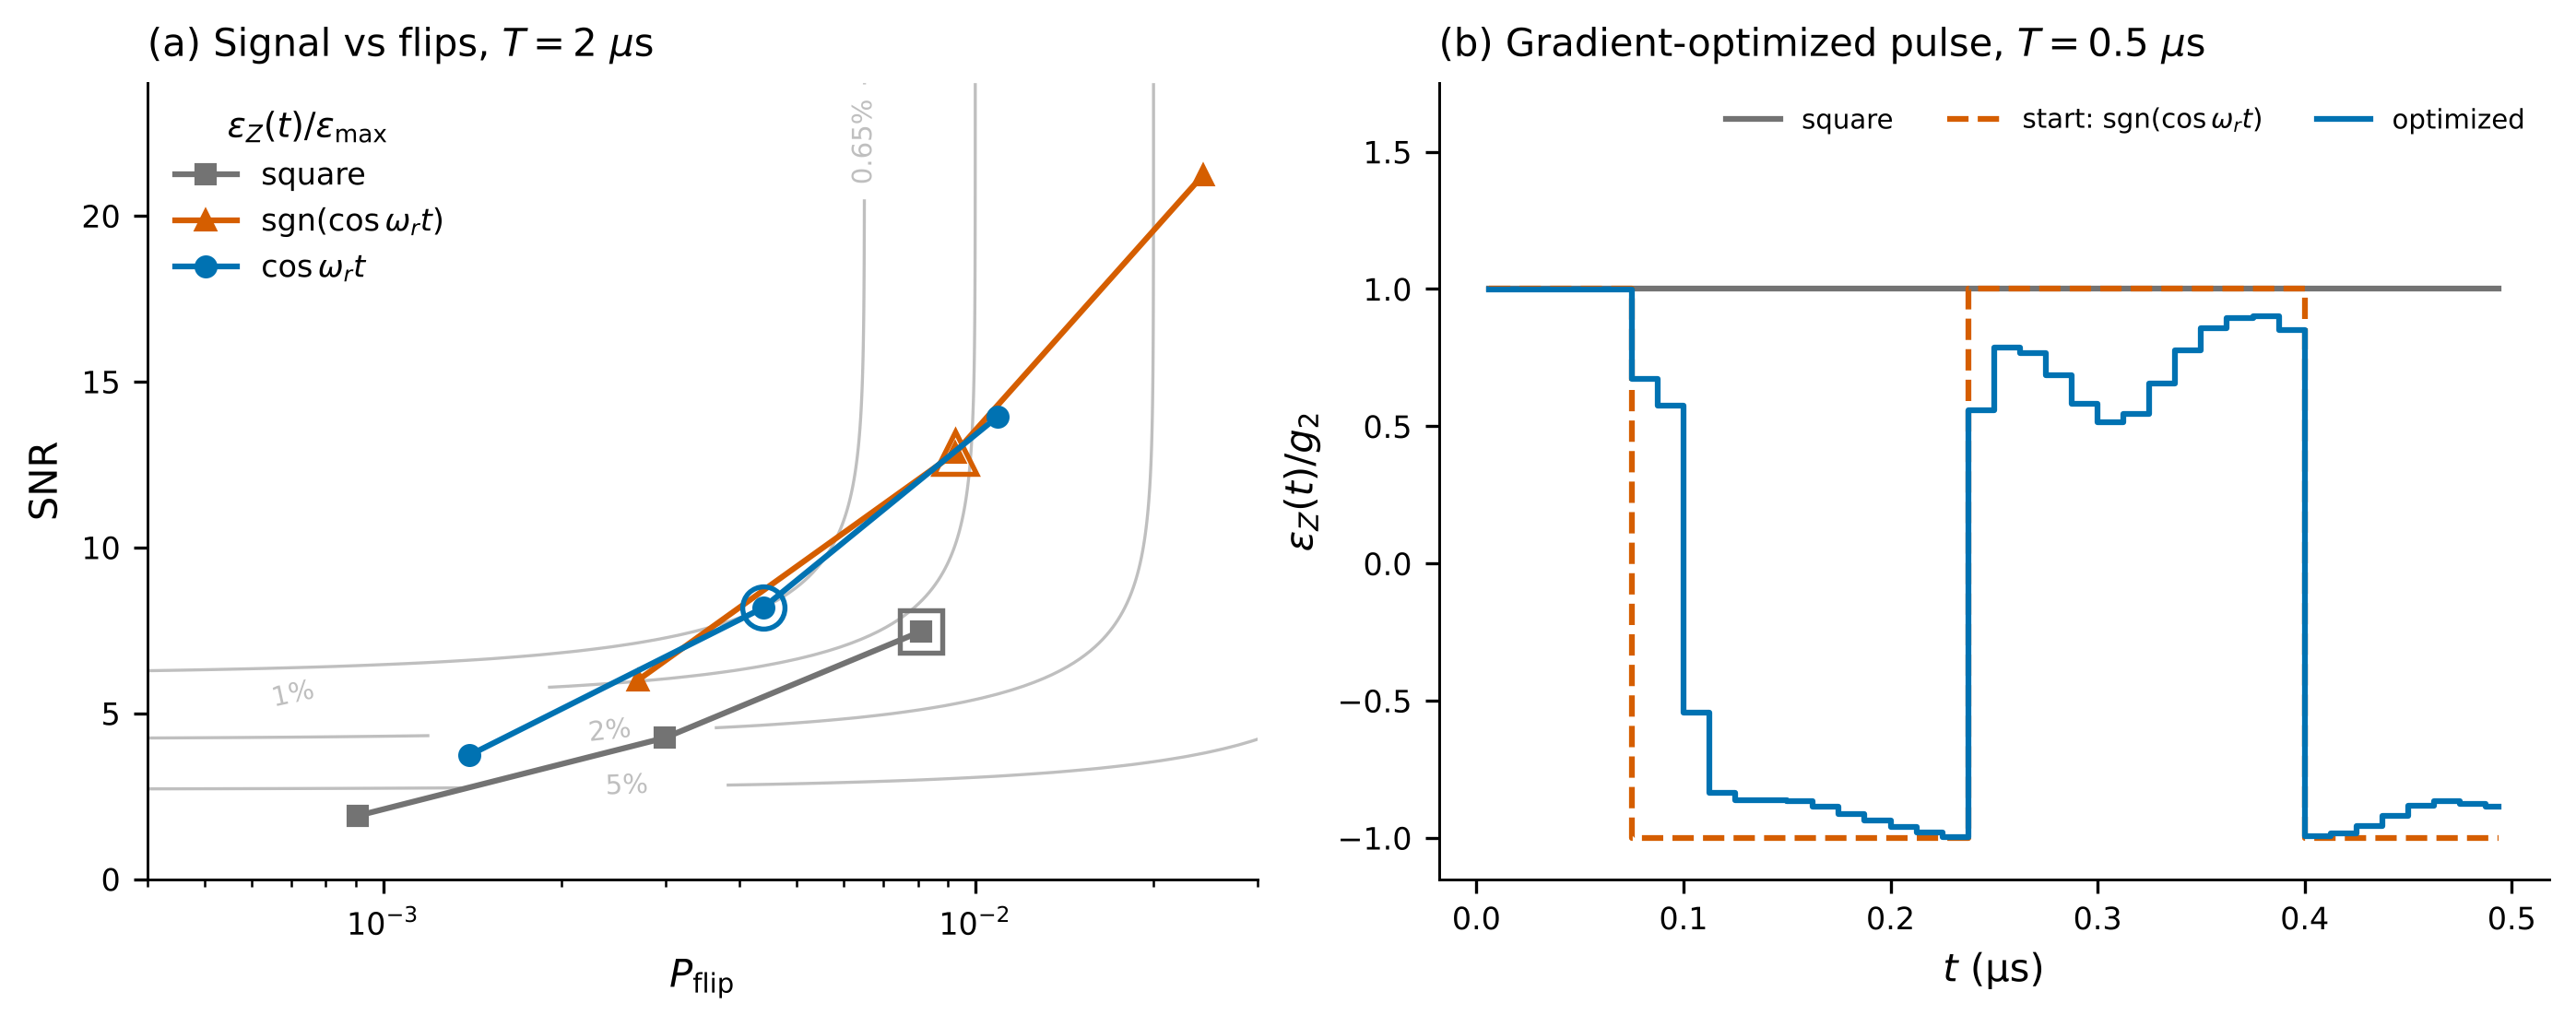

pulse,best peak (g₂),SNR,P_flip,ε_ro (η = 1),ε_ro (η = 0.5)
square,1,7.5,8.1e-03,1.12%,3.48%
cos ω_r t,0.75,8.2,4.4e-03,0.65%,1.50%
sgn(cos ω_r t),0.75,12.8,9.2e-03,0.94%,1.49%


In [5]:
with redirect_stdout(io.StringIO()):
    F.better_readout()
show("task_2_4_better_readout")
ps = F.load("pulse_a2.10_30x8_T2_peak.json")[0]
names = {"square": "square", "res": "cos ω_r t", "bang": "sgn(cos ω_r t)"}
rows = []
for f, name in names.items():
    fam = [r for r in ps["rows"] if r["family"] == f]
    b1 = min(fam, key=F.readout_error)
    b5 = min(fam, key=lambda r: F.readout_error(r, 0.5))
    rows.append({"pulse": name, "best peak (g₂)": f"{b1['level']:g}", "SNR": f"{b1['snr']:.1f}",
                 "P_flip": f"{b1['p_flip']:.1e}", "ε_ro (η = 1)": f"{100 * F.readout_error(b1):.2f}%",
                 "ε_ro (η = 0.5)": f"{100 * F.readout_error(b5, 0.5):.2f}%"})
display(pd.DataFrame(rows).style.hide(axis="index"))

**What this shows.** (a) Each curve walks left to right through peak $0.5$, $0.75$, $1g_2$: more drive, more signal, more flips. Gray lines are constant readout error. The resonant shapes sit *above* the square pulse: more signal for the same flips. The big open marker is each shape's best strength. (b) is the optimizer's pulse, which part (d) comes back to.

**Answer to (c).** Driving at the ringing frequency cuts the readout error in 2 µs from **1.12% to 0.65%** (ideal detector), and from **3.5% to 1.5%** with a 50% detector. It does not cost extra bit flips: the resonant cosine's best point has *fewer* flips than the square pulse's (4.4e-3 vs 8.1e-3). Check on the square number: its best peak sits at the edge of our scan; extrapolating with $\mathrm{SNR},P_{\rm flip}\propto\epsilon_Z^2$ moves its optimum to about 1.1%, so the gain holds.

## (d) Why it works: three independent pieces of evidence

> *Justify why your strategy works, using your simulations as evidence.*

### Evidence 1: the best pulse in the linear model is resonant, without us telling it to be

For small drives the buffer's response is linear in the pulse. Chop time into bins and it is a matrix:

$$\Delta b = K\,\epsilon\qquad(\epsilon=\text{the pulse, one number per bin})$$

Then $\mathrm{SNR}\propto\|K\epsilon\|^2$ and the drive cost $\propto\|\epsilon\|^2$ (part b). "Most signal for a fixed drive cost" is

$$\max_\epsilon\frac{\|K\epsilon\|^2}{\|\epsilon\|^2}\;\Rightarrow\;\epsilon^\star=\text{top singular vector of }K$$

Nothing in that recipe mentions a frequency. The next cell computes $\epsilon^\star$ (`research/s2/linresp.py:optimal_pulse`) and looks at what frequency it contains.

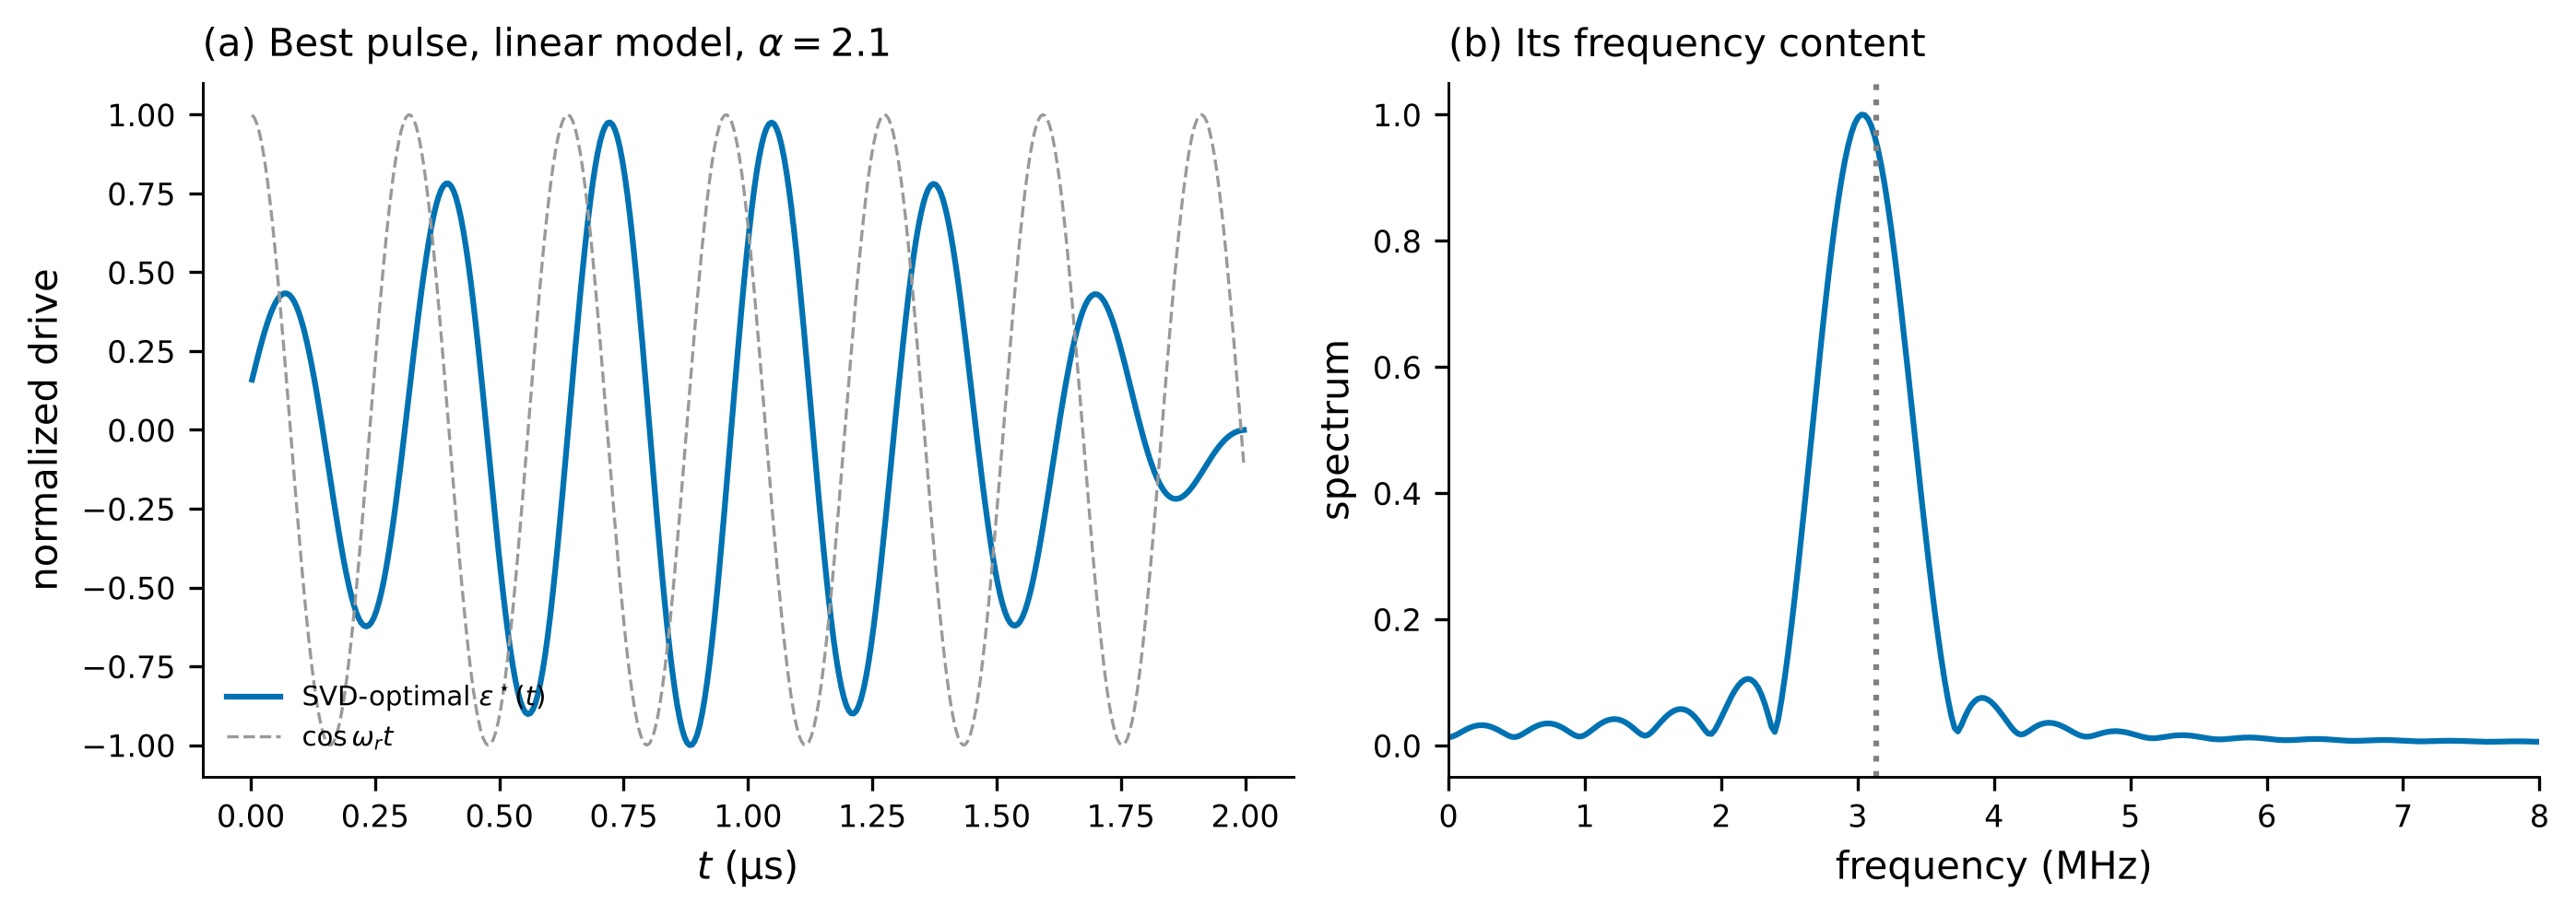

SVD pulse peaks at 3.03 MHz; ringing frequency ω_r/2π = 3.14 MHz


In [6]:
T, n = 2.0, 400
e_svd, _, dt = linresp.optimal_pulse(2.1, T, n, 1.0)
t = (np.arange(n) + 0.5) * dt
wr = np.sqrt(4 * G2**2 * 2.1**2 - KAPPA_B**2 / 16)
f = np.fft.rfftfreq(8192, dt); spec = np.abs(np.fft.rfft(e_svd, 8192))

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.2), layout="constrained")
ax[0].plot(t, e_svd / np.abs(e_svd).max(), color="C0", label=r"SVD-optimal $\epsilon^\star(t)$")
ax[0].plot(t, np.cos(wr * t), color="0.6", lw=0.8, ls="--", label=r"$\cos\omega_r t$")
ax[0].set(xlabel=r"$t$ (µs)", ylabel="normalized drive"); ax[0].legend(fontsize=7, loc="lower left")
P.panel(ax[0], "a", r"Best pulse, linear model, $\alpha=2.1$")
ax[1].plot(f, spec / spec.max(), color="C0"); ax[1].axvline(wr / (2 * pi), color="0.5", ls=":")
ax[1].set(xlabel="frequency (MHz)", ylabel="spectrum", xlim=(0, 8))
P.panel(ax[1], "b", "Its frequency content")
with redirect_stdout(io.StringIO()):
    P.save(fig, "s2/task_2_4_svd_pulse")
plt.close(fig); show("task_2_4_svd_pulse", 900)
print(f"SVD pulse peaks at {f[spec.argmax()]:.2f} MHz; ringing frequency ω_r/2π = {wr / (2 * pi):.2f} MHz")

The optimal pulse oscillates at the ringing frequency (its spectrum peaks within the window's resolution of $\omega_r/2\pi$), with a slowly varying envelope. So "drive in rhythm" is not a guess, it is what the math picks.

### Evidence 2: the full nonlinear simulation agrees

The linear model ignores the nonlinearity and the bit flips. Part (c) put the real pulses on the full two-mode model, flips included, and the resonant shapes still win (higher SNR at equal $P_{\rm flip}$).

### Evidence 3: an optimizer with full freedom stays resonant

`research/s2/pulse_opt.py` gives the pulse complete freedom (40 bins, each one a free number, bounded by $|\epsilon_Z|\le\epsilon_{\max}$ through $\epsilon=\epsilon_{\max}\tanh\theta$) and climbs

$$J=\mathrm{SNR}-\mu P_{\rm flip},\qquad\mu=\text{the square pulse's SNR per flip}$$

so a square pulse scores $J=0$ and anything positive beats it. Gradients come from `jax.grad` straight through the dynamiqs simulation. It starts from bang-bang. If resonance were the wrong idea, the optimizer would walk away from it. It doesn't: its pulse keeps flipping sign at the ringing period (part c, panel b).

In [7]:
opt = sorted((d for d in F.load("opt_*.json") if not d.get("partial") and d["nb"] >= 8),
             key=lambda d: (d["alpha"], d["T"], d["peak"]))
spf = lambda x: x["snr"] / x["p_flip"]
display(pd.DataFrame([{
    "α": d["alpha"], "T (µs)": d["T"], "ε_max (g₂)": d["peak"],
    "SNR/P_flip vs square": f"{spf(d['best']) / spf(d['square']):.2f}",
    "SNR/P_flip vs its start": f"{spf(d['best']) / spf(d['history'][0]):.2f}",
    "ε_ro square": f"{100 * F.readout_error(d['square']):.1f}%",
    "ε_ro start": f"{100 * F.readout_error(d['history'][0]):.1f}%",
    "ε_ro optimized": f"{100 * F.readout_error(d['best']):.1f}%",
} for d in opt]).style.hide(axis="index").format({"α": "{:g}", "T (µs)": "{:g}", "ε_max (g₂)": "{:g}"}))

α,T (µs),ε_max (g₂),SNR/P_flip vs square,SNR/P_flip vs its start,ε_ro square,ε_ro start,ε_ro optimized
1.4,0.5,0.5,1.55,1.02,18.4%,20.7%,18.7%
1.4,0.5,1,1.66,1.02,13.3%,10.0%,9.4%
1.4,1,0.5,1.59,1.02,13.7%,12.2%,10.9%
1.8,0.5,0.5,1.36,1.03,20.6%,19.1%,17.7%
1.8,0.5,1,1.71,1.14,6.5%,5.3%,5.1%
1.8,1,0.5,1.32,0.98,13.1%,8.0%,6.5%
2.1,0.5,0.5,1.26,1.05,23.3%,17.4%,18.5%
2.1,0.5,1,1.56,1.16,7.5%,3.5%,4.4%
2.1,1,0.5,1.30,1.11,16.1%,7.0%,9.8%


**Reading the optimizer table honestly.** Against a square pulse it gets 1.26 to 1.71× more signal per flip in all 9 settings. Most of that is the resonant starting point: against its own start it gains only 0.98 to 1.16×. By readout error it beats its start at $\alpha\le1.8$ but not at $\alpha=2.1$, because it was told to optimize signal per flip, not readout error. So the optimizer's job here is evidence, not the headline: given full freedom, it keeps the resonance.

### Why resonance helps, in one picture

The memory and buffer swap energy back and forth like two kids on a seesaw at about 3.1 MHz, and the buffer's leak is the friction (Task 2.3). The buffer is what we listen to. A square pulse pushes once and then just holds; the seesaw rings briefly and settles. A resonant pulse pushes again every half swing, so the buffer's swing builds up (by about $Q\approx2$) for the same drive. The flip cost tracks how much drive you put in (part b), the signal tracks how big the buffer swing gets, so the resonant pulse gets more signal per flip.

## Result

* **(a)** The readout drive is a tone at $\omega_a$ and enters as $\epsilon_Z(a+a^\dagger)$ with about 1% corrections. Besides $g_2a^2b^\dagger$ only small photon-number corrections survive the RWA; the pump's off-resonant push Stark-shifts the modes, so the real circuit needs the pump retuned by $-23$ MHz.
* **(b)** Contrast $\propto\epsilon_Z$ and $\Delta\Gamma_X=c(\alpha)\epsilon_Z^2$ with $c\propto e^{-2.03\alpha^2}$: signal and damage rise together, fixed by the pulse shape. The physical origin is the drive kicking the cat out of the code space.
* **(c)** Driving at the ringing frequency: readout error 1.12% → 0.65% in 2 µs ($\eta=1$), 3.5% → 1.5% ($\eta=0.5$), with no extra flips.
* **(d)** It works because the buffer is a ringing spring. The SVD-optimal pulse and the gradient optimizer both come out resonant.

**Limits.** The circuit simulation covers 150 ns without loss. $\epsilon_{\rm ro}$ assumes an ideal matched filter. Optimizer runs stop at 1 µs windows. The quasi-static estimate $\int\Gamma_X(\epsilon_Z(t))dt$ under-predicts the resonant pulse's flips by about 2× (ringing), so every flip number above comes from the full simulation.